# Nelson–Siegel–Svensson Treasury Curve (R)

Treasury yields are published at eleven maturities, but pricing and risk systems need a rate for every date. A parametric curve fills the gaps with a smooth shape whose few parameters have an economic meaning: level, slope and curvature. This notebook fits that curve by hand in base R, follows its factors for 26 years, and checks the result against the Federal Reserve's own fitted curve.

**What it does.** It fits the Nelson–Siegel and Nelson–Siegel–Svensson models to the daily Treasury constant-maturity curve with a hand-written estimator in base R (`optim`).

It fits the latest day and every month-end since 2000, tracks the level, slope and curvature factors, tests stability by leaving tenors out, and validates the fitted zero curve against the Federal Reserve's Gürkaynak–Sack–Wright (GSW) NSS curve.

**Data.** 11 constant-maturity Treasury yields from 1 month to 30 years (FRED via `fredr`), and the GSW zero-coupon curve and parameters (federalreserve.gov).

**Methods.** NS and NSS discount functions, with par yields computed from the discount function so the model is fitted on the same basis as the CMT data. The fit uses multi-start L-BFGS-B with bounds on the decay parameters.

Leave-one-tenor-out cross-validation and a comparison with GSW zero rates at 2, 5, 10 and 20 years check the result.

**Key output.** Today's fitted par, zero and forward curves, fit errors by tenor and model, 26 years of factor history, the gap to the Fed's curve, and an interactive dashboard.

## 1. Why a parametric curve

Treasury yields are observed at 11 maturities. Pricing, risk and scenario engines need a rate for every date. A parametric curve gives a smooth, economically readable answer:

$$
z(t)=\beta_0+\beta_1\,\frac{1-e^{-t/\tau_1}}{t/\tau_1}+\beta_2\left(\frac{1-e^{-t/\tau_1}}{t/\tau_1}-e^{-t/\tau_1}\right)+\beta_3\left(\frac{1-e^{-t/\tau_2}}{t/\tau_2}-e^{-t/\tau_2}\right)
$$

$\beta_0$ is the long-run level, $\beta_1$ the slope (short minus long), $\beta_2$ and $\beta_3$ two humps, and $\tau_1,\tau_2$ where the humps sit. Nelson–Siegel (1987) is the first three terms; Svensson (1994) added the second hump. The Fed publishes the GSW curve (Gürkaynak, Sack & Wright, 2007), an NSS curve fitted to off-the-run Treasury coupons, which is the natural benchmark.

CMT yields are **par yields** (bond-equivalent, semi-annual). Fitting a zero-curve formula directly to them mixes up two different curves, so here the NSS zero curve is turned into model par yields before comparing with the data.

## 2. Setup

In [1]:
# --- Packages (install once with `Rscript install_packages.R` from the repo
# root)
suppressPackageStartupMessages({
  library(tidyverse)
  library(scales)
  library(patchwork)
  library(plotly)
  library(htmlwidgets)
  library(jsonlite)
})
options(warn = 1, dplyr.summarise.inform = FALSE, repr.plot.width = 14,
        repr.plot.height = 5, repr.plot.res = 110)
# plain-text tables in the notebook (no ANSI colour codes)
options(crayon.enabled = FALSE, cli.num_colors = 1)

# --- Folders and credentials
PROJECT_DIR <- getwd()
DATA_DIR <- file.path(PROJECT_DIR,
                      "data"); OUT_DIR <- file.path(PROJECT_DIR, "outputs")
dir.create(DATA_DIR,
           showWarnings = FALSE); dir.create(OUT_DIR, showWarnings = FALSE)
# look for .env in this folder and its parents (like python-dotenv)
find_env <- function(start = getwd()) {
  d <- normalizePath(start)
  repeat {
    f <- file.path(d, ".env")
    if (file.exists(f)) return(f)
    parent <- dirname(d)
    if (parent == d) return(NA_character_)
    d <- parent
  }
}
env_file <- find_env()
# tolerate a missing final newline
if (!is.na(env_file)) suppressWarnings(dotenv::load_dot_env(env_file))

# --- Cache helper: every download is stored in data/ and reused for 12 hours
cached <- function(name, fetch, max_age_hours = 12) {
  path <- file.path(DATA_DIR, paste0(name, ".rds"))
  if (file.exists(path) &&
      difftime(Sys.time(), file.mtime(path),
               units = "hours") < max_age_hours) return(readRDS(path))
  out <- tryCatch(fetch(), error = function(e) {
    if (file.exists(path)) { message(name, ": download failed (",
                                     conditionMessage(e),
                                     "); using cached copy"); return(readRDS(path)) }
    stop(e)
  })
  saveRDS(out, path)
  out
}

# --- Chart style (consistent palette across all charts)
PALETTE <- c("#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
             "#6250d6", "#e34948")
INK <- "#0b0b0b"; INK_2 <- "#52514e"; GRID <- "#e4e3df"; SURFACE <- "#fcfcfb"
STATUS <- c(green = "#1baf7a", amber = "#eda100", red = "#e34948")
theme_risk <- function() {
  theme_minimal(base_size = 11) +
    theme(plot.background = element_rect(fill = SURFACE, colour = NA),
          panel.background = element_rect(fill = SURFACE, colour = NA),
          panel.grid.major = element_line(colour = GRID),
            panel.grid.minor = element_blank(),
          plot.title = element_text(face = "bold", colour = INK, size = 12),
            plot.title.position = "plot",
          axis.text = element_text(colour = INK_2),
            axis.title = element_text(colour = INK_2),
          legend.position = "top", legend.title = element_blank())
}
theme_set(theme_risk())
save_fig <- function(p, name, width = 14,
                     height = 5) ggsave(file.path(
                         OUT_DIR, paste0(name, ".png")),
                                        p, width = width, height = height,
                                        dpi = 150, bg = SURFACE)

# Interactive dashboard as a single HTML file that loads plotly.js from a CDN
# (no pandoc needed)
save_plotly_html <- function(widget, name, title) {
  b <- plotly_build(widget)$x
  if (is.null(b$layout$height)) b$layout$height <- 900
  html <- sprintf('<!doctype html><html><head><meta charset="utf-8"><title>%s</title>
<script src="https://cdn.plot.ly/plotly-2.35.2.min.js"></script></head>
<body style="background:%s;margin:0"><div id="dash" style="width:100%%;height:95vh"></div>
<script>var fig=%s;Plotly.newPlot("dash",fig.data,fig.layout,{responsive:true});</script></body></html>',
                  title, SURFACE,
                    toJSON(list(data = b$data, layout = b$layout),
                           auto_unbox = TRUE, null = "null", na = "null",
                           force = TRUE, digits = NA))
  writeLines(html, file.path(OUT_DIR, paste0(name, ".html")))
  message("Dashboard saved: outputs/", name, ".html")
}

suppressPackageStartupMessages(library(fredr))
fredr_set_key(Sys.getenv("FRED_API_KEY"))
if (Sys.getenv("FRED_API_KEY") == "") stop("FRED_API_KEY not found: create the .env file at the repo root")
CMT <- c(DGS1MO = 1 / 12, DGS3MO = 0.25, DGS6MO = 0.5, DGS1 = 1, DGS2 = 2,
         DGS3 = 3, DGS5 = 5, DGS7 = 7, DGS10 = 10, DGS20 = 20, DGS30 = 30)
START <- as.Date("2000-01-01")
N_STARTS <- 12
set.seed(3)
cat(sprintf("R %s · fredr %s · run on %s\n", getRversion(),
            packageVersion("fredr"), Sys.Date()))

R 4.3.3 · fredr 2.1.0 · run on 2026-10-19


## 3. Data

In [2]:
cmt <- cached("fred_cmt", function() {
  map_dfr(
    names(CMT),
    function(id) fredr(series_id = id, observation_start = START) %>%
      transmute(date, tenor = CMT[[id]], yield = value)
  )
}) %>% filter(!is.na(yield))
wide <- cmt %>%
  pivot_wider(names_from = tenor, values_from = yield) %>%
  arrange(date)
# 20-year CMT was not published 1987-1993 and the 30-year paused 2002-2006: the
# fit uses whatever tenors exist on the day
gsw <- cached("fed_gsw", function() {
  txt <- readLines("https://www.federalreserve.gov/data/yield-curve-tables/feds200628.csv",
    warn = FALSE
  )
  hdr <- grep("^Date,", txt)[1]
  read_csv(I(paste(txt[hdr:length(txt)], collapse = "\n")),
    show_col_types = FALSE, na = c("NA", "")
  )
}, max_age_hours = 24 * 7) %>% mutate(Date = as.Date(Date))
latest <- max(wide$date)
cat(sprintf(
  "CMT: %d days %s → %s · GSW: %d days to %s\n", nrow(wide),
  min(wide$date), latest, nrow(gsw), max(gsw$Date)
))
wide %>% filter(date == latest)

CMT: 6701 days 2000-01-03 → 2026-10-16 · GSW: 17043 days to 2026-10-09


date,0.0833333333333333,0.25,0.5,1,2,3,5,7,10,20,30
<date>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2026-10-16,4.12,4.26,4.34,4.46,4.74,4.82,4.89,4.98,5.09,5.47,5.43


## 4. The estimator

For parameters $\theta$, the model discount factor is $P(t)=e^{-z(t)\,t}$. The model par yield at maturity $T \ge 1$ is $c(T)=2\,\frac{1-P(T)}{\sum_{k=1}^{2T} P(k/2)}$, and for bills ($T<1$) the bond-equivalent yield of $P(T)$. Parameters minimise the sum of squared par-yield errors, using `optim` (L-BFGS-B) from 12 random starts within bounds ($\beta_0 \in [0, 15]$, $\tau_1 \in [0.1, 5]$, $\tau_2 \in [5, 30]$), keeping the best.

Restricting $\tau_2$ to the long end keeps the two humps apart, which is what GSW do too.

In [3]:
nss_zero <- function(t, p) {
  b0 <- p[1]; b1 <- p[2]; b2 <- p[3]; t1 <- p[4]
  x1 <- t / t1; h1 <- (1 - exp(-x1)) / x1
  z <- b0 + b1 * h1 + b2 * (h1 - exp(-x1))
  if (length(p) == 6) {
    x2 <- t / p[6]; h2 <- (1 - exp(-x2)) / x2; z <- z + p[5] * (h2 - exp(-x2))
  }
  z
}
model_par <- function(T, p) {
  sapply(T, function(Ti) {
    if (Ti < 1) {
      P <- exp(-nss_zero(Ti, p) / 100 * Ti)
      # bond-equivalent yield of a bill
      return(100 * 2 * (P^(-1 / (2 * Ti)) - 1))
    }
    tk <- seq(0.5, Ti, by = 0.5)
    P <- exp(-nss_zero(tk, p) / 100 * tk)
    100 * 2 * (1 - P[length(P)]) / sum(P)
  })
}
fit_curve <- function(T, y, model = c("NSS", "NS"), starts = N_STARTS) {
  model <- match.arg(model)
  lower <- if (model == "NSS") c(0, -15, -30, 0.1, -30, 5) else c(
    0, -15, -30,
    0.1
  )
  upper <- if (model == "NSS") c(15, 15, 30, 5, 30, 30) else c(15, 15, 30, 5)
  obj <- function(p) sum((model_par(T, p) - y)^2)
  best <- NULL
  for (s in seq_len(starts)) {
    p0 <- c(
      max(y[T >= 10], na.rm = TRUE), y[1] - max(y), runif(1, -3, 3),
      runif(1, 0.3, 4)
    )
    if (model == "NSS") p0 <- c(p0, runif(1, -3, 3), runif(1, 6, 25))
    p0 <- pmin(pmax(p0, lower + 1e-6), upper - 1e-6)
    f <- tryCatch(optim(p0, obj, method = "L-BFGS-B", lower = lower,
                        upper = upper, control = list(maxit = 500)),
      error = function(e) NULL
    )
    if (!is.null(f) && (is.null(best) || f$value < best$value)) best <- f
  }
  list(
    par = best$par, rmse_bp = sqrt(best$value / length(y)) * 100,
    fitted = model_par(T, best$par)
  )
}

today <- cmt %>%
  filter(date == latest) %>%
  arrange(tenor)
fits_today <- list(
  NS = fit_curve(today$tenor, today$yield, "NS"),
  NSS = fit_curve(today$tenor, today$yield, "NSS")
)
tibble(
  tenor = today$tenor, CMT = today$yield, `NS fit` = fits_today$NS$fitted,
  `NSS fit` = fits_today$NSS$fitted
) %>%
  mutate(
    `NS error (bp)` = (`NS fit` - CMT) * 100,
    `NSS error (bp)` = (`NSS fit` - CMT) * 100
  ) %>%
  mutate(across(where(is.numeric), ~ round(.x, 3)))

tenor,CMT,NS fit,NSS fit,NS error (bp),NSS error (bp)
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.083,4.12,4.223,4.134,10.271,1.445
0.250,4.26,4.264,4.223,0.379,-3.674
0.500,4.34,4.322,4.338,-1.751,-0.178
1.000,4.46,4.429,4.512,-3.098,5.227
2.000,4.74,4.607,4.714,-13.301,-2.648
3.000,4.82,4.747,4.809,-7.256,-1.114
5.000,4.89,4.949,4.897,5.862,0.664
7.000,4.98,5.080,4.973,9.996,-0.742
10.000,5.09,5.202,5.114,11.242,2.353


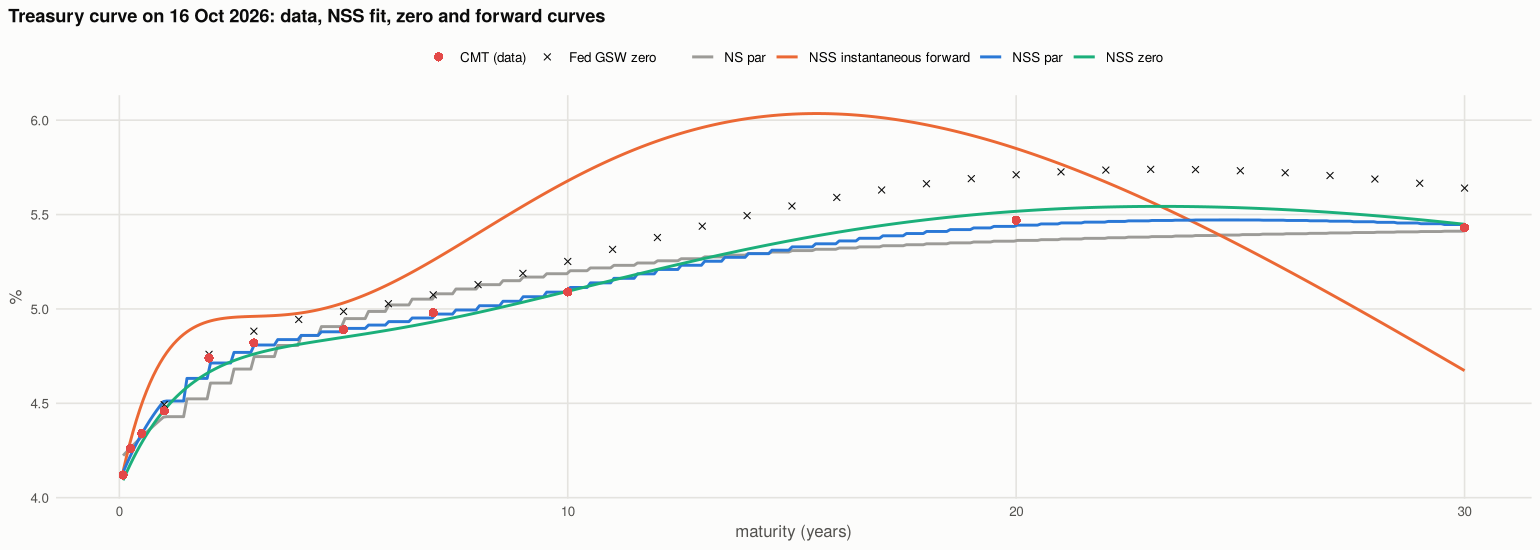

In [4]:
# --- Chart 1: today's par, zero and forward curves
tt <- seq(1 / 12, 30, length.out = 400)
p <- fits_today$NSS$par
# instantaneous forward
fwd <- function(t, p, h = 1e-4) (nss_zero(t + h, p) * (t + h) -
  nss_zero(t, p) * t) /
  h
curves <- tibble(
  t = tt, `NSS par` = model_par(tt, p), `NSS zero` = nss_zero(tt, p),
  `NSS instantaneous forward` = fwd(tt, p),
  `NS par` = model_par(tt, fits_today$NS$par)
) %>% pivot_longer(-t)
g_today <- gsw %>% filter(Date == max(Date[Date <= latest]))
gsw_zero <- tibble(
  t = 1:30,
  z = unlist(g_today[
    1,
    paste0("SVENY", sprintf("%02d", 1:30))
  ])
)
p_today <- ggplot() +
  geom_line(data = curves, aes(t, value, colour = name), linewidth = 0.9) +
  geom_point(
    data = gsw_zero, aes(t, z, shape = "Fed GSW zero"), colour = INK,
    size = 1.6
  ) +
  geom_point(
    data = today, aes(tenor, yield, shape = "CMT (data)"),
    colour = STATUS[["red"]], size = 2.5
  ) +
  scale_colour_manual(values = c(
    `NSS par` = PALETTE[1],
    `NSS zero` = PALETTE[3],
    `NSS instantaneous forward` = PALETTE[2],
    `NS par` = "#9c9b97"
  )) +
  scale_shape_manual(values = c(`CMT (data)` = 16, `Fed GSW zero` = 4)) +
  labs(
    x = "maturity (years)", y = "%",
    title = sprintf(
      "Treasury curve on %s: data, NSS fit, zero and forward curves",
      format(latest, "%d %b %Y")
    )
  )
save_fig(p_today, "01_curve_today")
print(p_today)

## 5. Twenty-six years of month-end fits

NS and NSS are fitted on every month-end since 2000 (each fit uses the tenors available that day). The table summarises fit quality; the chart tracks the factors. For readability the "level", "slope" and "curvature" shown are the model's 10-year zero rate, the 10-year minus 3-month zero spread, and twice the 2-year zero minus the 3-month and 10-year zeros. Raw $\beta$s trade off against each other, especially in NSS.

In [5]:
month_ends <- wide %>%
  group_by(ym = format(date, "%Y-%m")) %>%
  summarise(date = max(date), .groups = "drop") %>%
  pull(date)
t0 <- Sys.time()
hist_fits <- map_dfr(month_ends, function(d) {
  x <- cmt %>%
    filter(date == d) %>%
    arrange(tenor)
  if (nrow(x) < 7) return(NULL)
  ns <- fit_curve(x$tenor, x$yield, "NS",
    starts = 4
  ); nss <- fit_curve(x$tenor, x$yield, "NSS",
    starts = 5
  )
  z <- function(t) nss_zero(t, nss$par)
  tibble(
    date = d, n_tenors = nrow(x), `NS RMSE (bp)` = ns$rmse_bp,
    `NSS RMSE (bp)` = nss$rmse_bp,
    level = z(10), slope = z(10) - z(0.25), curvature = 2 * z(2) - z(0.25) -
      z(10),
    b0 = nss$par[1], b1 = nss$par[2], b2 = nss$par[3], tau1 = nss$par[4],
    b3 = nss$par[5], tau2 = nss$par[6],
    z2 = z(2), z5 = z(5), z10 = z(10), z20 = z(20)
  )
})
cat(sprintf(
  "%d month-end fits (NS + NSS) in %.0f s\n", nrow(hist_fits),
  as.numeric(difftime(Sys.time(), t0, units = "secs"))
))
hist_fits %>%
  summarise(across(
    c(`NS RMSE (bp)`, `NSS RMSE (bp)`),
    list(
      median = median, p90 = ~ quantile(.x, 0.9),
      max = max
    )
  )) %>%
  pivot_longer(everything()) %>%
  mutate(value = round(value, 2))

322 month-end fits (NS + NSS) in 738 s


name,value
<chr>,<dbl>
NS RMSE (bp)_median,4.85
NS RMSE (bp)_p90,9.56
NS RMSE (bp)_max,21.73
NSS RMSE (bp)_median,3.22
NSS RMSE (bp)_p90,6.07
NSS RMSE (bp)_max,18.51


## 6. Validation: leave-one-tenor-out and the Fed's curve

**Leave one tenor out:** on each of the last 36 month-ends, every tenor between 3 months and 20 years is dropped in turn, the curve refitted, and the dropped yield predicted. That measures how well each model interpolates, which is how a curve is used.

**GSW benchmark:** our NSS zero rates at 2, 5, 10 and 20 years are compared with the Fed's on the same dates. The two are fitted to different data (CMT par yields vs individual off-the-run coupon bonds), so a gap of a few basis points is expected and its pattern is informative.

In [6]:
recent <- tail(month_ends, 36)
loo <- map_dfr(recent, function(d) {
  x <- cmt %>%
    filter(date == d) %>%
    arrange(tenor)
  map_dfr(which(x$tenor >= 0.25 & x$tenor <= 20), function(k) {
    tr <- x[-k, ]
    map_dfr(c("NS", "NSS"), function(m) {
      f <- fit_curve(tr$tenor, tr$yield, m, starts = 3)
      tibble(
        date = d, model = m, tenor = x$tenor[k],
        error_bp = (model_par(x$tenor[k], f$par) - x$yield[k]) * 100
      )
    })
  })
})
loo_tab <- loo %>%
  group_by(model, tenor) %>%
  summarise(`LOO RMSE (bp)` = sqrt(mean(error_bp^2)), .groups = "drop") %>%
  pivot_wider(names_from = model, values_from = `LOO RMSE (bp)`)
gsw_cmp <- hist_fits %>%
  inner_join(
    gsw %>%
      transmute(date = Date, g2 = SVENY02, g5 = SVENY05, g10 = SVENY10,
                g20 = SVENY20),
    by = "date"
  ) %>%
  transmute(date,
    `2y` = (z2 - g2) * 100, `5y` = (z5 - g5) * 100,
    `10y` = (z10 - g10) * 100, `20y` = (z20 - g20) * 100
  )
gsw_sum <- gsw_cmp %>%
  pivot_longer(-date, names_to = "tenor", values_to = "gap_bp") %>%
  group_by(tenor) %>%
  summarise(
    `mean gap (bp)` = mean(gap_bp, na.rm = TRUE),
    `mean |gap| (bp)` = mean(abs(gap_bp), na.rm = TRUE),
    `last 3y mean gap` = mean(gap_bp[date >= max(date) - 3 * 365],
                              na.rm = TRUE),
    .groups = "drop"
  )
print(loo_tab %>% mutate(across(where(is.numeric), ~ round(.x, 2))))
gsw_sum %>% mutate(across(where(is.numeric), ~ round(.x, 2)))

# A tibble: 9 × 3
  tenor    NS   NSS
  <dbl> <dbl> <dbl>
1  0.25  4.76  4.11
2  0.5   6.81  5.86
3  1     5.2   5.09
4  2     7.24  4.17
5  3     5.31  3.82
6  5     3.81  1.96
7  7     5     3.71
8 10     7.29  8.55
9 20    15.0  14.1 


tenor,mean gap (bp),mean |gap| (bp),last 3y mean gap
<chr>,<dbl>,<dbl>,<dbl>
10y,-7.24,7.80,-0.09
20y,-7.00,7.60,-1.25
2y,-0.98,2.66,-1.95
5y,-2.36,3.11,-2.38


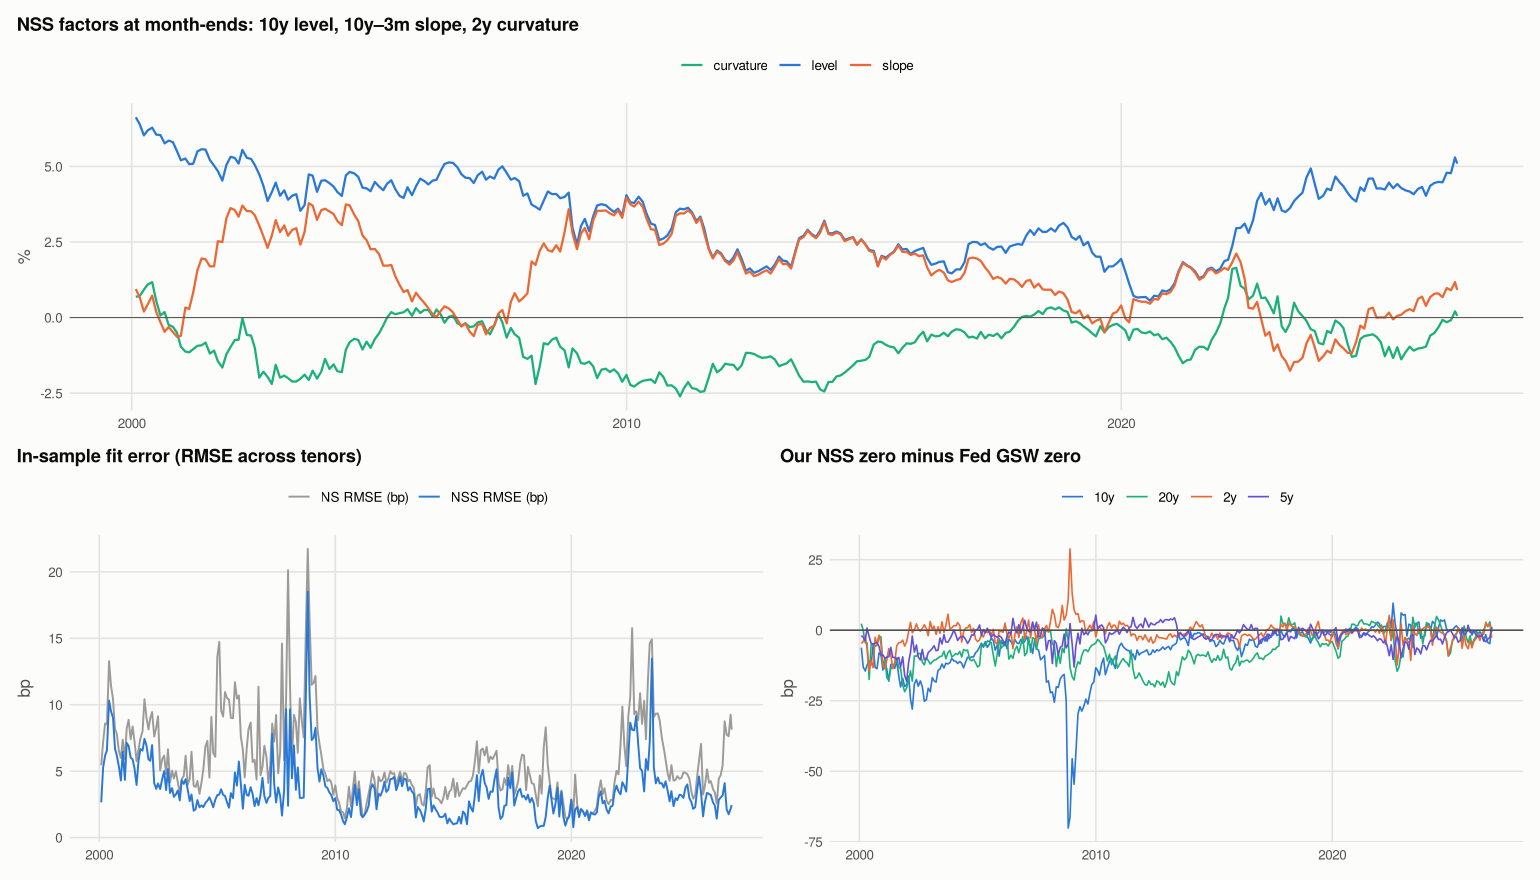

In [7]:
# --- Chart 2: factor history, fit errors and the GSW gap
fac <- hist_fits %>% select(date, level, slope, curvature) %>%
  pivot_longer(-date)
p_fac <- ggplot(fac, aes(date, value, colour = name)) +
  geom_line(linewidth = 0.7) +
  geom_hline(yintercept = 0, colour = INK_2, linewidth = 0.3) +
  scale_colour_manual(values = c(level = PALETTE[1], slope = PALETTE[2],
                                 curvature = PALETTE[3])) +
  labs(x = NULL, y = "%",
       title = "NSS factors at month-ends: 10y level, 10y–3m slope, 2y curvature")
p_err <- ggplot(hist_fits %>% select(date, `NS RMSE (bp)`, `NSS RMSE (bp)`) %>%
                pivot_longer(-date), aes(date, value, colour = name)) +
  geom_line(linewidth = 0.6) +
    scale_colour_manual(values = c(`NS RMSE (bp)` = "#9c9b97",
                                   `NSS RMSE (bp)` = PALETTE[1])) +
  labs(x = NULL, y = "bp", title = "In-sample fit error (RMSE across tenors)")
p_gsw <- ggplot(gsw_cmp %>% pivot_longer(-date),
                aes(date, value, colour = name)) +
  geom_line(linewidth = 0.5) +
  geom_hline(yintercept = 0, colour = INK_2) +
    scale_colour_manual(values = PALETTE[c(1, 3, 2, 7)]) +
  labs(x = NULL, y = "bp", title = "Our NSS zero minus Fed GSW zero")
fig2 <- p_fac / (p_err | p_gsw)
save_fig(fig2, "02_history_errors_gsw", height = 8)
options(repr.plot.height = 8); print(fig2); options(repr.plot.height = 5)

## 7. Results dashboard

Dashboard saved: outputs/dashboard.html



Outputs: 01_curve_today.png, 02_history_errors_gsw.png, dashboard.html, dashboard.png, gap_vs_fed_gsw.csv, leave_one_tenor_out.csv, monthly_nss_fits.csv, nss_parameters_today.csv 


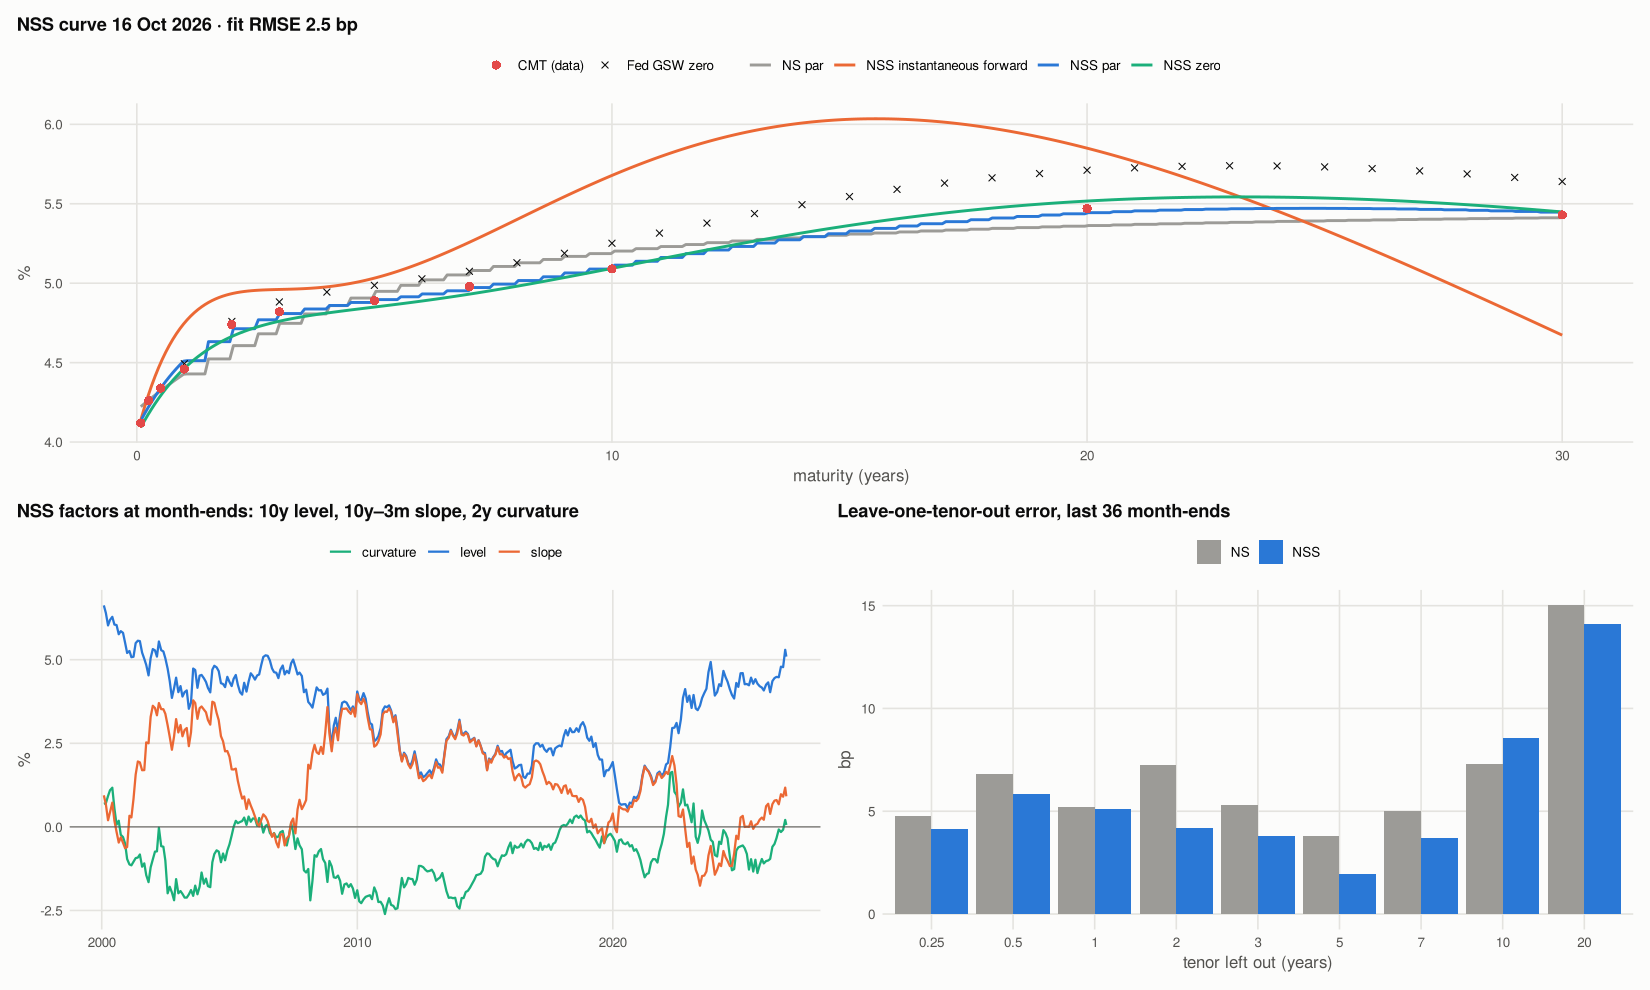

In [8]:
d1 <- curves %>%
  filter(name %in% c("NSS par", "NSS zero", "NSS instantaneous forward"))
pl1 <- plot_ly() %>%
  add_lines(
    data = d1, x = ~t, y = ~value, color = ~name,
    colors = c(PALETTE[1], PALETTE[3], PALETTE[2])
  ) %>%
  add_markers(
    data = today, x = ~tenor, y = ~yield, name = "CMT data",
    marker = list(color = STATUS[["red"]], size = 9)
  ) %>%
  add_markers(
    data = gsw_zero, x = ~t, y = ~z, name = "Fed GSW zero",
    marker = list(color = INK, symbol = "x", size = 6)
  )
pl2 <- plot_ly(hist_fits, x = ~date) %>%
  add_lines(
    y = ~level, name = "level (10y zero)",
    line = list(color = PALETTE[1])
  ) %>%
  add_lines(
    y = ~slope, name = "slope (10y–3m)",
    line = list(color = PALETTE[2])
  ) %>%
  add_lines(
    y = ~curvature, name = "curvature",
    line = list(color = PALETTE[3])
  )
pl3 <- plot_ly(loo_tab,
  x = ~ factor(tenor), y = ~NS, type = "bar",
  name = "NS leave-one-out RMSE",
  marker = list(color = "#9c9b97")
) %>%
  add_bars(
    y = ~NSS, name = "NSS leave-one-out RMSE",
    marker = list(color = PALETTE[1])
  )
dash <- subplot(pl1, subplot(pl2, pl3, nrows = 1, widths = c(0.6, 0.4)),
  nrows = 2, margin = 0.07
) %>%
  layout(
    title = list(x = 0.01, text = sprintf(
      "<b>Treasury NSS curve · %s</b><br><span style='font-size:13px'>NSS fit RMSE %.1f bp (NS %.1f bp) · median month-end NSS RMSE %.1f bp · mean |gap| to Fed GSW at 10y %.1f bp</span>",
      format(latest, "%d %b %Y"), fits_today$NSS$rmse_bp,
      fits_today$NS$rmse_bp, median(hist_fits$`NSS RMSE (bp)`),
      gsw_sum$`mean |gap| (bp)`[gsw_sum$tenor == "10y"]
    )),
    paper_bgcolor = SURFACE, plot_bgcolor = SURFACE, margin = list(t = 110),
    barmode = "group", legend = list(orientation = "h", y = -0.05)
  )
save_plotly_html(dash, "dashboard", "Treasury NSS curve")
dash_png <- (p_today +
  labs(title = sprintf(
    "NSS curve %s · fit RMSE %.1f bp",
    format(latest, "%d %b %Y"),
    fits_today$NSS$rmse_bp
  ))) /
  (p_fac | (ggplot(
    loo %>% group_by(model, tenor) %>%
      summarise(rmse = sqrt(mean(error_bp^2)), .groups = "drop"),
    aes(factor(tenor), rmse, fill = model)
  ) +
    geom_col(position = "dodge") +
    scale_fill_manual(values = c(NS = "#9c9b97", NSS = PALETTE[1])) +
    labs(
      x = "tenor left out (years)", y = "bp",
      title = "Leave-one-tenor-out error, last 36 month-ends"
    )))
save_fig(dash_png, "dashboard", width = 15, height = 9)
options(repr.plot.width = 15, repr.plot.height = 9)
print(dash_png) # the static dashboard, shown here as well as saved
write_csv(hist_fits, file.path(OUT_DIR, "monthly_nss_fits.csv"))
write_csv(loo_tab, file.path(OUT_DIR, "leave_one_tenor_out.csv"))
write_csv(gsw_sum, file.path(OUT_DIR, "gap_vs_fed_gsw.csv"))
write_csv(
  tibble(parameter = c("beta0", "beta1", "beta2", "tau1", "beta3", "tau2"),
         NSS = fits_today$NSS$par),
  file.path(OUT_DIR, "nss_parameters_today.csv")
)
cat("Outputs:", paste(list.files(OUT_DIR), collapse = ", "), "\n")

## 8. Reading the results and limitations

Eleven constant-maturity Treasury yields, 1 month to 30 years, fitted on 16 October 2026 and at 322 month-ends since January 2000:

**NSS fits the curve to within a few basis points; NS does not.** Today NSS has an RMSE of 2.5 bp and no tenor misses by more than 5 bp. NS has 8.1 bp, missing the 2-year by 13 bp and the 10-year and 20-year by about 11 bp: one hump is not enough for today's curve, which rises to 20 years and dips at 30.

Across 26 years of month-ends the median RMSE is 3.2 bp for NSS against 4.8 bp for NS, with the worst fits in 2000–2001, 2008 and 2022 (5–6 bp medians), when the short end moved fastest.

- **The factors tell the rate history.** Level, measured as the fitted 10-year zero rate, fell from 6.6% in 2000 to 0.56% in July 2020 and is about 5.1% today. Slope (10-year minus 3-month) bottomed at −1.76 points in May 2023, the deepest inversion of the sample, and is back to +0.9 points.

**Out of sample the fit is weaker at the long end.** Leaving one tenor out and predicting it from the rest gives errors of 2–6 bp from 3 months to 7 years for NSS. The error is 8.5 bp at 10 years and 14 bp at 20 years, where few points anchor the second hump.

NSS beats NS on every left-out tenor except 10 years. For pricing off-the-run bonds at long maturities, the curve should be built from more points (all coupon securities, as the Fed does) than from the 11 CMT tenors.

**The fitted zero curve agrees with the Fed's within a few basis points.** Against the Gürkaynak–Sack–Wright zero rates the mean absolute gap is 2.7 bp at 2 years, 3.1 bp at 5 years and about 7.7 bp at 10 and 20 years. The long-end gap averages −7 bp over 26 years but almost zero over the last three.

The two curves are built differently: GSW uses off-the-run coupon bonds, while CMT par yields come from on-the-run issues, which carry a liquidity premium.

**The NSS parameters are not individually identified.** Today β0 sits at its lower bound (0) and β3 = 16 with τ2 = 16 years. GSW's own published parameters look the same (β0 ≈ 0, β3 ≈ 17). With a long second decay, the β3 term behaves like a second level, so β0 and β3 trade off with almost no change in fit.

At 13% of month-ends β0 hits zero, and a few fits jump between solutions (May 2000 is one). That is why the factor history is built from fitted zero rates, which are stable, rather than from the β's. A risk system that stores and shocks NSS parameters directly would inherit this instability.

**Limitations**

- CMT yields are themselves interpolated par yields from on-the-run securities, not traded bond prices; a production curve would fit bond prices with their own coupons.
- The multi-start optimiser is bounded (τ1 0.1–5 years, τ2 5–30 years); different bounds give different parameters with the same fit.
- Month-end fits only; daily fits would add noise around auctions and month-end.

## References

### Finance and regulation

- Nelson, C. R., & Siegel, A. F. (1987). Parsimonious modeling of yield curves. *The Journal of Business, 60*(4), 473–489. https://doi.org/10.1086/296409
- Svensson, L. E. O. (1994). *Estimating and interpreting forward interest rates: Sweden 1992–1994* (NBER Working Paper No. 4871). National Bureau of Economic Research. https://doi.org/10.3386/w4871
- Gürkaynak, R. S., Sack, B., & Wright, J. H. (2007). The U.S. Treasury yield curve: 1961 to the present. *Journal of Monetary Economics, 54*(8), 2291–2304. https://doi.org/10.1016/j.jmoneco.2007.06.029
- Bank for International Settlements. (2005). *Zero-coupon yield curves: Technical documentation* (BIS Papers No. 25). https://www.bis.org/publ/bppdf/bispap25.htm
- Diebold, F. X., & Li, C. (2006). Forecasting the term structure of government bond yields. *Journal of Econometrics, 130*(2), 337–364. https://doi.org/10.1016/j.jeconom.2005.03.005

### Machine learning and deep learning

- Byrd, R. H., Lu, P., Nocedal, J., & Zhu, C. (1995). A limited memory algorithm for bound constrained optimization. *SIAM Journal on Scientific Computing, 16*(5), 1190–1208. https://doi.org/10.1137/0916069
- Arlot, S., & Celisse, A. (2010). A survey of cross-validation procedures for model selection. *Statistics Surveys, 4*, 40–79. https://doi.org/10.1214/09-SS054